In [ ]:
# Cell 1 — Environment setup
!nvidia-smi

from google.colab import drive
drive.mount('/content/drive')

!pip install -q segmentation-models-pytorch albumentations onnx onnxruntime codecarbon grad-cam

Sat Nov  7 14:29:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os, platform, torch
import segmentation_models_pytorch as smp
import albumentations as A
import onnxruntime as ort

PROJECT_DIR = '/content/drive/MyDrive/IPCVai_MedSeg'
for sub in ['data', 'checkpoints', 'results', 'onnx', 'figures']:
    os.makedirs(f'{PROJECT_DIR}/{sub}', exist_ok=True)

print('Python      :', platform.python_version())
print('PyTorch     :', torch.__version__, '| CUDA:', torch.cuda.is_available())
print('GPU         :', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None')
print('CPU cores   :', os.cpu_count())
print('smp         :', smp.__version__)
print('albumentations:', A.__version__)
print('onnxruntime :', ort.__version__)
print('Project dir :', PROJECT_DIR)

Python      : 3.13.16
PyTorch     : 2.14.1+cu130 | CUDA: True
GPU         : Tesla T4
CPU cores   : 2
smp         : 0.6.0
albumentations: 2.0.8
onnxruntime : 1.31.1
Project dir : /content/drive/MyDrive/IPCVai_MedSeg


In [ ]:
# Cell 2a — Download Kvasir-SEG (fallback for the server's certificate issue)
import os, zipfile

ZIP_DRIVE = f'{PROJECT_DIR}/data/kvasir-seg.zip'
URL = 'https://datasets.simula.no/downloads/kvasir-seg.zip'

# Remove any partial file from the failed attempt
if os.path.exists(ZIP_DRIVE) and os.path.getsize(ZIP_DRIVE) < 40_000_000:
    os.remove(ZIP_DRIVE)

if not os.path.exists(ZIP_DRIVE):
    # Try with normal certificate checks first; fall back only if that fails
    rc = os.system(f'wget -q -O "{ZIP_DRIVE}" "{URL}"')
    if rc != 0:
        print('Normal download failed -> retrying without certificate check')
        os.system(f'wget -q --no-check-certificate -O "{ZIP_DRIVE}" "{URL}"')

# Make sure the file is a real, complete zip
size_mb = os.path.getsize(ZIP_DRIVE) / 1e6
with zipfile.ZipFile(ZIP_DRIVE) as z:
    bad = z.testzip()
    n_img = sum(1 for n in z.namelist() if '/images/' in n and n.endswith('.jpg'))
    n_msk = sum(1 for n in z.namelist() if '/masks/' in n and n.endswith('.jpg'))
print(f'Size: {size_mb:.1f} MB | Corrupt file: {bad} | images: {n_img} | masks: {n_msk}')

Normal download failed -> retrying without certificate check
Size: 46.2 MB | Corrupt file: None | images: 1000 | masks: 1000


Contents: ['kavsir_bboxes.json', 'masks', 'images']
Images: 1000 | Missing masks: 0
Height  min/median/max: 352 / 530 / 1072
Width   min/median/max: 332 / 621 / 1920
Polyp area % min/median/max: 0.47 / 11.40 / 81.18
Empty masks: 0
Avg non-binary mask pixels (JPEG artefacts): 0.000%
Split -> train 800 | val 100 | test 100


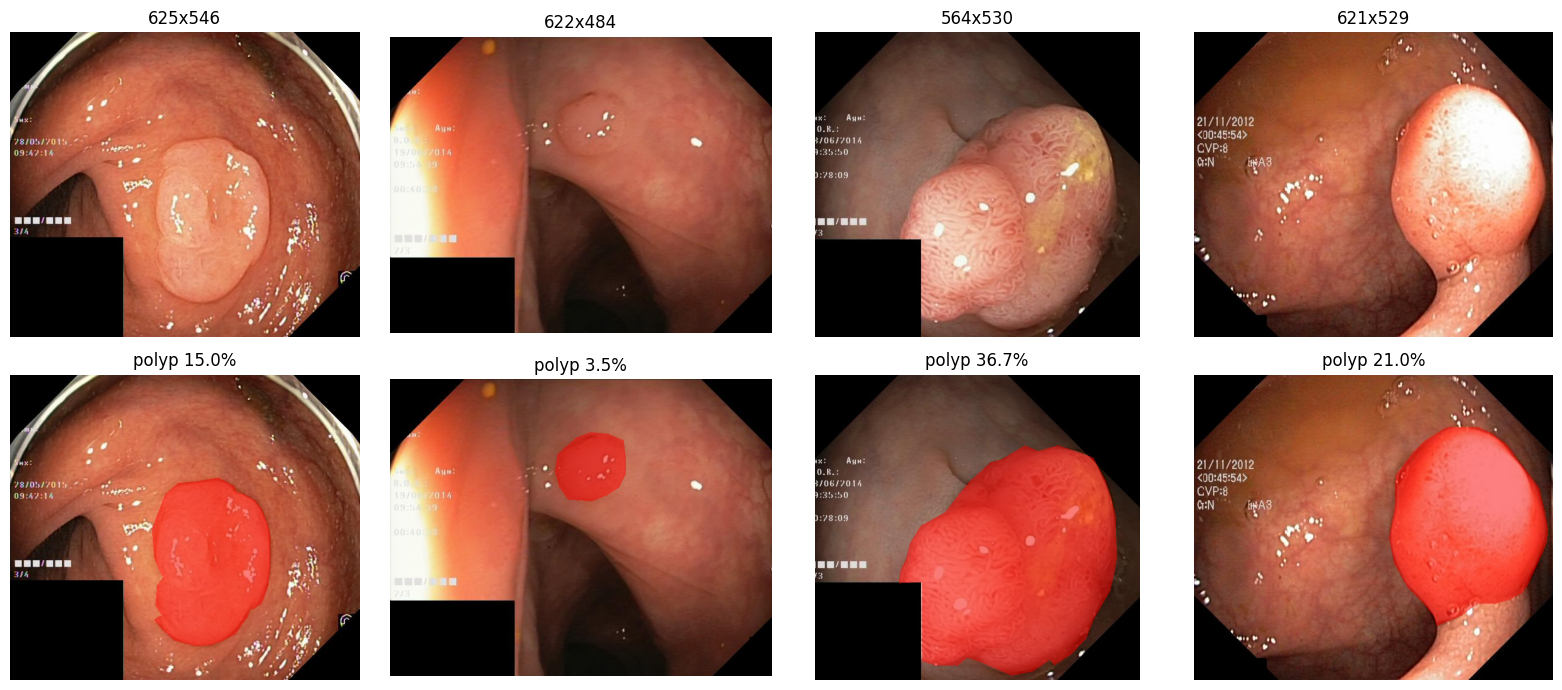

In [ ]:
# Cell 2 — Download, inspect and split Kvasir-SEG
import os, glob, json, zipfile, urllib.request
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

URL       = 'https://datasets.simula.no/downloads/kvasir-seg.zip'
ZIP_DRIVE = f'{PROJECT_DIR}/data/kvasir-seg.zip'
DATA_DIR  = '/content/Kvasir-SEG'
SEED      = 42

# 1. Download once to Drive, extract to fast local disk
if not os.path.exists(ZIP_DRIVE):
    print('Downloading...')
    urllib.request.urlretrieve(URL, ZIP_DRIVE)
if not os.path.exists(DATA_DIR):
    with zipfile.ZipFile(ZIP_DRIVE) as z:
        z.extractall('/content')
print('Contents:', os.listdir(DATA_DIR))

# 2. Pair images with masks
img_paths = sorted(glob.glob(f'{DATA_DIR}/images/*.jpg'))
ids = [os.path.splitext(os.path.basename(p))[0] for p in img_paths]
missing = [i for i in ids if not os.path.exists(f'{DATA_DIR}/masks/{i}.jpg')]
print(f'Images: {len(ids)} | Missing masks: {len(missing)}')

# 3. Inspect sizes, polyp area, JPEG mask noise
heights, widths, areas, noisy = [], [], [], []
for i in ids:
    m = np.array(Image.open(f'{DATA_DIR}/masks/{i}.jpg').convert('L'))
    heights.append(m.shape[0]); widths.append(m.shape[1])
    areas.append((m > 127).mean())
    noisy.append(((m > 10) & (m < 245)).mean())
heights, widths, areas = map(np.array, (heights, widths, areas))

print(f'Height  min/median/max: {heights.min()} / {int(np.median(heights))} / {heights.max()}')
print(f'Width   min/median/max: {widths.min()} / {int(np.median(widths))} / {widths.max()}')
print(f'Polyp area % min/median/max: {areas.min()*100:.2f} / {np.median(areas)*100:.2f} / {areas.max()*100:.2f}')
print(f'Empty masks: {(areas == 0).sum()}')
print(f'Avg non-binary mask pixels (JPEG artefacts): {np.mean(noisy)*100:.3f}%')

# 4. Stratified 800/100/100 split by polyp-size quartile
bins = np.digitize(areas, np.quantile(areas, [0.25, 0.5, 0.75]))
train_ids, temp_ids, _, temp_bins = train_test_split(
    ids, bins, test_size=200, stratify=bins, random_state=SEED)
val_ids, test_ids = train_test_split(
    temp_ids, test_size=100, stratify=temp_bins, random_state=SEED)

split = {'seed': SEED, 'train': sorted(train_ids), 'val': sorted(val_ids), 'test': sorted(test_ids)}
with open(f'{PROJECT_DIR}/data/split.json', 'w') as f:
    json.dump(split, f, indent=2)
print(f'Split -> train {len(train_ids)} | val {len(val_ids)} | test {len(test_ids)}')

# 5. Visualise 4 samples with mask overlay
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for k, i in enumerate(np.random.RandomState(SEED).choice(ids, 4, replace=False)):
    img = np.array(Image.open(f'{DATA_DIR}/images/{i}.jpg').convert('RGB'))
    msk = np.array(Image.open(f'{DATA_DIR}/masks/{i}.jpg').convert('L')) > 127
    over = img.copy(); over[msk] = (0.5 * over[msk] + [127, 0, 0]).astype(np.uint8)
    axes[0, k].imshow(img);  axes[0, k].set_title(f'{img.shape[1]}x{img.shape[0]}')
    axes[1, k].imshow(over); axes[1, k].set_title(f'polyp {msk.mean()*100:.1f}%')
    for a in axes[:, k]: a.axis('off')
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/figures/samples.png', dpi=120)
plt.show()

Cached all splits in 3.7s
Batch image: (16, 3, 352, 352) torch.float32 | range [-2.12, 2.64]
Batch mask : (16, 1, 352, 352) torch.float32 | values [0.0, 1.0] | polyp 12.8%
Batches -> train 50 | val 7 | test 7
One full train epoch of data loading: 3.5s


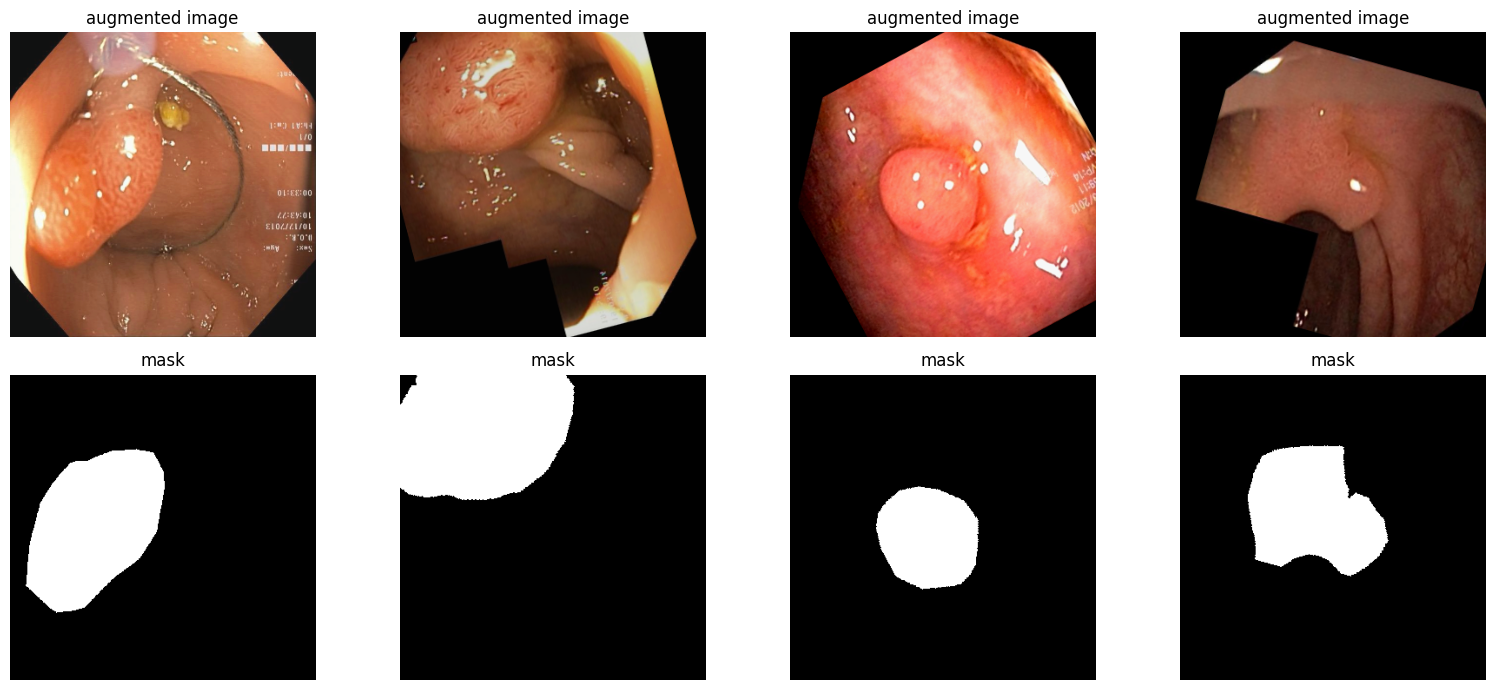

In [ ]:
# Cell 3 — Dataset, augmentations and DataLoaders
import cv2, time, random, torch
from torch.utils.data import Dataset, DataLoader
from albumentations.pytorch import ToTensorV2

IMG_SIZE, BATCH = 352, 16
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

# 1. Load + resize every image once into RAM (~370 MB) -> fast epochs on 2 CPU cores
def load_resized(i):
    img = cv2.cvtColor(cv2.imread(f'{DATA_DIR}/images/{i}.jpg'), cv2.COLOR_BGR2RGB)
    msk = cv2.imread(f'{DATA_DIR}/masks/{i}.jpg', cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    msk = (cv2.resize(msk, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR) > 127).astype(np.uint8)
    return img, msk

t0 = time.time()
cache = {s: [load_resized(i) for i in split[s]] for s in ['train', 'val', 'test']}
print(f'Cached all splits in {time.time()-t0:.1f}s')

# 2. Augmentations (train only)
train_tf = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Affine(scale=(0.85, 1.15), translate_percent=(-0.06, 0.06), rotate=(-30, 30), p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.02, p=0.5),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])
eval_tf = A.Compose([A.Normalize(mean=MEAN, std=STD), ToTensorV2()])

# 3. Dataset
class PolypDataset(Dataset):
    def __init__(self, items, tf):
        self.items, self.tf = items, tf
    def __len__(self):
        return len(self.items)
    def __getitem__(self, k):
        img, msk = self.items[k]
        out = self.tf(image=img, mask=msk)
        return out['image'], out['mask'].unsqueeze(0).float()

g = torch.Generator().manual_seed(SEED)
loader_kw = dict(num_workers=2, pin_memory=True, persistent_workers=True)
train_loader = DataLoader(PolypDataset(cache['train'], train_tf), batch_size=BATCH,
                          shuffle=True, drop_last=True, generator=g, **loader_kw)
val_loader   = DataLoader(PolypDataset(cache['val'],  eval_tf), batch_size=BATCH, shuffle=False, **loader_kw)
test_loader  = DataLoader(PolypDataset(cache['test'], eval_tf), batch_size=BATCH, shuffle=False, **loader_kw)

# 4. Sanity checks
x, y = next(iter(train_loader))
print(f'Batch image: {tuple(x.shape)} {x.dtype} | range [{x.min():.2f}, {x.max():.2f}]')
print(f'Batch mask : {tuple(y.shape)} {y.dtype} | values {torch.unique(y).tolist()} | polyp {y.mean()*100:.1f}%')
print(f'Batches -> train {len(train_loader)} | val {len(val_loader)} | test {len(test_loader)}')

t0 = time.time()
for _ in train_loader: pass
print(f'One full train epoch of data loading: {time.time()-t0:.1f}s')

# 5. Show 4 augmented samples
def denorm(t):
    return np.clip(t.permute(1, 2, 0).numpy() * STD + MEAN, 0, 1)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for k in range(4):
    axes[0, k].imshow(denorm(x[k])); axes[0, k].set_title('augmented image')
    axes[1, k].imshow(y[k, 0], cmap='gray'); axes[1, k].set_title('mask')
    for a in axes[:, k]: a.axis('off')
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/figures/augmented_batch.png', dpi=120)
plt.show()

In [ ]:
# Cell 4a — Remove possibly corrupted teacher checkpoints (run ONCE, never on resume)
for f in ['teacher_r34_best.pt', 'teacher_r34_last.pt', 'teacher_r34_last.pt.tmp']:
    p = f'{PROJECT_DIR}/checkpoints/{f}'
    if os.path.exists(p):
        os.remove(p); print('Removed', f)

Removed teacher_r34_best.pt


In [ ]:
# Cell 4 — Training engine + teacher model (U-Net ResNet34) — Drive-safe saving
import math, json, shutil, torch.nn as nn, torch.nn.functional as F
torch.backends.cudnn.benchmark = True
DEVICE = 'cuda'
LOCAL_CKPT = '/content/ckpt_local'
os.makedirs(LOCAL_CKPT, exist_ok=True)

# ---------- Safe saving: local disk first, then copy to Drive ----------
def safe_save(obj, drive_path, to_drive=True):
    local = f'{LOCAL_CKPT}/{os.path.basename(drive_path)}'
    torch.save(obj, local)
    if not to_drive:
        return
    for _ in range(3):
        try:
            shutil.copyfile(local, drive_path + '.tmp')
            os.replace(drive_path + '.tmp', drive_path)
            return
        except OSError:
            time.sleep(3)
    print(f'  [warn] Drive copy failed for {os.path.basename(drive_path)} (local copy kept)')

def load_ckpt(drive_path):
    local = f'{LOCAL_CKPT}/{os.path.basename(drive_path)}'
    path = local if os.path.exists(local) else drive_path
    return torch.load(path, map_location=DEVICE, weights_only=False)

# ---------- Model ----------
def build_model(encoder, weights='imagenet'):
    return smp.Unet(encoder_name=encoder, encoder_weights=weights, in_channels=3, classes=1)

def count_params(m):
    return sum(p.numel() for p in m.parameters()) / 1e6

# ---------- Losses ----------
dice_loss = smp.losses.DiceLoss(mode='binary', from_logits=True)
bce_loss  = nn.BCEWithLogitsLoss()

def seg_loss(logits, y):
    return dice_loss(logits, y) + bce_loss(logits, y)

def kd_loss(s_logits, t_logits, T=2.0):          # used later for the student
    return F.binary_cross_entropy_with_logits(s_logits / T, torch.sigmoid(t_logits / T)) * T * T

# ---------- Metrics (per-image, then averaged = mDice / mIoU) ----------
@torch.no_grad()
def per_image_scores(logits, y, thr=0.5):
    p = (torch.sigmoid(logits) > thr).float()
    inter = (p * y).sum((1, 2, 3)); ps = p.sum((1, 2, 3)); ys = y.sum((1, 2, 3))
    dice = (2 * inter + 1e-7) / (ps + ys + 1e-7)
    iou  = (inter + 1e-7) / (ps + ys - inter + 1e-7)
    return dice, iou

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); dices, ious, losses = [], [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast('cuda', dtype=torch.float16):
            logits = model(x)
        logits = logits.float()
        losses.append(seg_loss(logits, y).item() * len(x))
        d, i = per_image_scores(logits, y); dices.append(d); ious.append(i)
    n = len(loader.dataset)
    return sum(losses) / n, torch.cat(dices).mean().item(), torch.cat(ious).mean().item()

# ---------- Training loop ----------
def train_model(name, model, epochs=100, lr=3e-4, warmup=3, patience=25,
                teacher=None, alpha=0.5, T=2.0, drive_every=5):
    model = model.to(DEVICE)
    if teacher is not None:
        teacher = teacher.to(DEVICE).eval()
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    lr_lambda = lambda e: (e + 1) / warmup if e < warmup else \
        0.5 * (1 + math.cos(math.pi * (e - warmup) / max(1, epochs - warmup)))
    sched  = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    scaler = torch.amp.GradScaler('cuda')

    best_path = f'{PROJECT_DIR}/checkpoints/{name}_best.pt'
    last_path = f'{PROJECT_DIR}/checkpoints/{name}_last.pt'
    hist_path = f'{PROJECT_DIR}/results/{name}_history.json'
    start, best, bad, hist = 0, -1.0, 0, []

    if os.path.exists(last_path) or os.path.exists(f'{LOCAL_CKPT}/{name}_last.pt'):
        ck = load_ckpt(last_path)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
        sched.load_state_dict(ck['sched']); scaler.load_state_dict(ck['scaler'])
        start, best, bad, hist = ck['epoch'], ck['best'], ck['bad'], ck['hist']
        print(f'Resumed {name} from epoch {start} (best val Dice {best:.4f})')

    print(f'{name}: {count_params(model):.2f}M params | epochs {epochs} | KD: {teacher is not None}')
    t_total = time.time()
    for ep in range(start, epochs):
        model.train(); t0 = time.time(); run_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda', dtype=torch.float16):
                logits = model(x)
                loss = seg_loss(logits.float(), y)
                if teacher is not None:
                    with torch.no_grad():
                        t_logits = teacher(x)
                    loss = (1 - alpha) * loss + alpha * kd_loss(logits.float(), t_logits.float(), T)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            run_loss += loss.item()
        sched.step()

        v_loss, v_dice, v_iou = evaluate(model, val_loader)
        rec = dict(epoch=ep + 1, train_loss=run_loss / len(train_loader), val_loss=v_loss,
                   val_dice=v_dice, val_iou=v_iou, lr=opt.param_groups[0]['lr'], sec=time.time() - t0)
        hist.append(rec)

        flag = ''
        if v_dice > best:
            best, bad, flag = v_dice, 0, ' *best'
            safe_save(model.state_dict(), best_path)
        else:
            bad += 1
        print(f"ep {ep+1:03d} | train {rec['train_loss']:.4f} | val {v_loss:.4f} | "
              f"Dice {v_dice:.4f} | IoU {v_iou:.4f} | lr {rec['lr']:.1e} | {rec['sec']:.0f}s{flag}")

        stop = bad >= patience
        last_epoch = stop or ep + 1 == epochs
        safe_save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                       scaler=scaler.state_dict(), epoch=ep + 1, best=best, bad=bad, hist=hist),
                  last_path, to_drive=((ep + 1) % drive_every == 0) or last_epoch)
        try:
            with open(hist_path, 'w') as f:
                json.dump(hist, f, indent=1)
        except OSError:
            pass
        if stop:
            print(f'Early stopping at epoch {ep+1}')
            break

    print(f'Done in {(time.time()-t_total)/60:.1f} min | best val Dice {best:.4f}')
    model.load_state_dict(load_ckpt(best_path))
    return model, hist

# ---------- Train the teacher ----------
# set_seed()
# teacher, teacher_hist = train_model('teacher_r34', build_model('resnet34'), epochs=100)
# v_loss, v_dice, v_iou = evaluate(teacher, val_loader)
# print(f'\nTeacher (best ckpt) on VAL -> Dice {v_dice:.4f} | IoU {v_iou:.4f}')

**Cell R — Restore state**

In [ ]:
# Cell R — Restore state after disconnect (run after Cells 1-3 and Cell 4 WITHOUT its training block)
import subprocess
from scipy.stats import wilcoxon

# Teacher (best checkpoint from Drive)
teacher = build_model('resnet34', weights=None)
teacher.load_state_dict(load_ckpt(f'{PROJECT_DIR}/checkpoints/teacher_r34_v2_best.pt'))
teacher = teacher.to(DEVICE).eval()

def build_student():
    return smp.Unet(encoder_name='mobilenet_v2', encoder_weights='imagenet', in_channels=3,
                    classes=1, decoder_channels=(128, 64, 32, 16, 16))

def summary(name, hist, model):
    _, d, i = evaluate(model, val_loader)
    b = max(hist, key=lambda r: r['val_dice'])
    print(f"{name:<22} best ep {b['epoch']:>3} | best Dice {d:.4f} IoU {i:.4f} | "
          f"last-epoch Dice {hist[-1]['val_dice']:.4f}")

# Test-set helpers (native resolution scoring)
test_ids = split['test']
orig_masks  = {i: cv2.imread(f'{DATA_DIR}/masks/{i}.jpg', cv2.IMREAD_GRAYSCALE) > 127 for i in test_ids}
test_inputs = {i: eval_tf(image=img, mask=msk)['image'].unsqueeze(0).numpy()
               for i, (img, msk) in zip(test_ids, cache['test'])}

def dice_iou_np(p, g):
    inter = np.logical_and(p, g).sum(); s = p.sum() + g.sum()
    return (2 * inter + 1e-7) / (s + 1e-7), (inter + 1e-7) / (s - inter + 1e-7)

def native_scores(logits_352, i):
    g = orig_masks[i]
    prob = 1 / (1 + np.exp(-logits_352[0, 0]))
    prob = cv2.resize(prob, (g.shape[1], g.shape[0]), interpolation=cv2.INTER_LINEAR)
    return dice_iou_np(prob > 0.5, g)

@torch.no_grad()
def torch_native_dice(model):
    model = model.float().to(DEVICE).eval()
    return np.array([native_scores(model(torch.from_numpy(test_inputs[i]).to(DEVICE)).cpu().numpy(), i)[0]
                     for i in test_ids])

def paired(a, b, label):
    diff = a - b
    rng = np.random.default_rng(SEED)
    boots = [rng.choice(diff, len(diff), replace=True).mean() for _ in range(10000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    p = wilcoxon(a, b).pvalue
    print(f"{label:<34} mean diff {diff.mean()*100:+.2f} pts | 95% CI [{lo*100:+.2f}, {hi*100:+.2f}] | Wilcoxon p = {p:.4f}")
    return dict(comparison=label, mean_diff=float(diff.mean()), ci_low=float(lo), ci_high=float(hi), p_value=float(p))

# Sanity check — should print ~0.9003
_, d, _ = evaluate(teacher, val_loader)
print(f'Teacher restored | val Dice {d:.4f}')
print('Saved checkpoints:', sorted(f for f in os.listdir(f'{PROJECT_DIR}/checkpoints') if f.startswith('student')))

Teacher restored | val Dice 0.9003
Saved checkpoints: ['student_mnv2_kd_best.pt', 'student_mnv2_kd_last.pt', 'student_mnv2_kd_s43_best.pt', 'student_mnv2_kd_s43_last.pt', 'student_mnv2_plain_best.pt', 'student_mnv2_plain_last.pt', 'student_mnv2_plain_s43_best.pt', 'student_mnv2_plain_s43_last.pt']


**Cell 5 — Teacher v2 with a full cosine schedule**

In [ ]:
# Cell 5 — Teacher v2: full cosine schedule, no early stopping
set_seed()
teacher_v2, hist_v2 = train_model('teacher_r34_v2', build_model('resnet34'),
                                  epochs=60, patience=999)

def summary(name, hist, model):
    _, d, i = evaluate(model, val_loader)
    b = max(hist, key=lambda r: r['val_dice'])
    print(f"{name:<22} best ep {b['epoch']:>3} | best Dice {d:.4f} IoU {i:.4f} | "
          f"last-epoch Dice {hist[-1]['val_dice']:.4f}")

print()
summary('v1 (early-stopped)', teacher_hist, teacher)
summary('v2 (full cosine, 60)', hist_v2, teacher_v2)

teacher_r34_v2: 24.44M params | epochs 60 | KD: False
ep 001 | train 1.1269 | val 0.9128 | Dice 0.6624 | IoU 0.5221 | lr 2.0e-04 | 14s *best
ep 002 | train 0.8335 | val 0.7382 | Dice 0.7614 | IoU 0.6501 | lr 3.0e-04 | 13s *best
ep 003 | train 0.6691 | val 0.5531 | Dice 0.8161 | IoU 0.7183 | lr 3.0e-04 | 14s *best
ep 004 | train 0.5336 | val 0.4955 | Dice 0.8062 | IoU 0.7234 | lr 3.0e-04 | 13s
ep 005 | train 0.4379 | val 0.3977 | Dice 0.8314 | IoU 0.7526 | lr 3.0e-04 | 13s *best
ep 006 | train 0.4078 | val 0.4343 | Dice 0.7968 | IoU 0.6971 | lr 3.0e-04 | 13s
ep 007 | train 0.3827 | val 0.4254 | Dice 0.7857 | IoU 0.6998 | lr 3.0e-04 | 13s
ep 008 | train 0.3402 | val 0.3845 | Dice 0.8235 | IoU 0.7424 | lr 2.9e-04 | 13s
ep 009 | train 0.3144 | val 0.3180 | Dice 0.8307 | IoU 0.7581 | lr 2.9e-04 | 13s
ep 010 | train 0.3014 | val 0.3521 | Dice 0.8296 | IoU 0.7533 | lr 2.9e-04 | 13s
ep 011 | train 0.2806 | val 0.2943 | Dice 0.8577 | IoU 0.7842 | lr 2.9e-04 | 13s *best
ep 012 | train 0.2688 | v

**Cell 6 — Student without and with knowledge distillation**

In [ ]:
# Cell 6 — Student: U-Net MobileNetV2 (slim decoder), without vs with KD
teacher = teacher_v2.eval()
TEACHER_NAME = 'teacher_r34_v2'

def build_student():
    return smp.Unet(encoder_name='mobilenet_v2', encoder_weights='imagenet', in_channels=3,
                    classes=1, decoder_channels=(128, 64, 32, 16, 16))

print(f'Teacher params: {count_params(teacher):.2f}M | '
      f'Student params: {count_params(build_student()):.2f}M')

# Run A — student alone
set_seed()
student_plain, hist_plain = train_model('student_mnv2_plain', build_student(),
                                        epochs=60, patience=999)

# Run B — student + distillation from the teacher
set_seed()
student_kd, hist_kd = train_model('student_mnv2_kd', build_student(),
                                  epochs=60, patience=999,
                                  teacher=teacher, alpha=0.5, T=2.0)

print()
summary('teacher r34 v2', hist_v2, teacher)
summary('student (no KD)', hist_plain, student_plain)
summary('student (KD)', hist_kd, student_kd)

config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Teacher params: 24.44M | Student params: 4.14M
student_mnv2_plain: 4.14M params | epochs 60 | KD: False
ep 001 | train 1.3288 | val 1.1481 | Dice 0.5671 | IoU 0.4262 | lr 2.0e-04 | 30s *best
ep 002 | train 0.9463 | val 0.8368 | Dice 0.7215 | IoU 0.6030 | lr 3.0e-04 | 10s *best
ep 003 | train 0.6893 | val 0.5841 | Dice 0.7862 | IoU 0.6743 | lr 3.0e-04 | 10s *best
ep 004 | train 0.5174 | val 0.4179 | Dice 0.8308 | IoU 0.7493 | lr 3.0e-04 | 10s *best
ep 005 | train 0.4088 | val 0.3812 | Dice 0.8423 | IoU 0.7525 | lr 3.0e-04 | 11s *best
ep 006 | train 0.3478 | val 0.3111 | Dice 0.8434 | IoU 0.7709 | lr 3.0e-04 | 10s *best
ep 007 | train 0.3058 | val 0.3075 | Dice 0.8449 | IoU 0.7634 | lr 3.0e-04 | 9s *best
ep 008 | train 0.2887 | val 0.2842 | Dice 0.8535 | IoU 0.7795 | lr 2.9e-04 | 10s *best
ep 009 | train 0.2645 | val 0.2925 | Dice 0.8454 | IoU 0.7655 | lr 2.9e-04 | 9s
ep 010 | train 0.2861 | val 0.2915 | Dice 0.8479 | IoU 0.7717 | lr 2.9e-04 | 10s
ep 011 | train 0.2347 | val 0.2631 | Dic

In [ ]:
# Cell 7 — Export to ONNX (FP32) + static INT8 quantization + validation accuracy
import copy, onnx
from onnxruntime.quantization import (quantize_static, CalibrationDataReader, QuantFormat,
                                      QuantType, CalibrationMethod)
from onnxruntime.quantization.shape_inference import quant_pre_process

ONNX_DIR = '/content/onnx_local'
os.makedirs(ONNX_DIR, exist_ok=True)

# ---------- 1. Export FP32 + parity check ----------
def export_onnx(model, path):
    m = copy.deepcopy(model).float().cpu().eval()
    dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    kw = dict(input_names=['image'], output_names=['logits'], opset_version=17,
              dynamic_axes={'image': {0: 'batch'}, 'logits': {0: 'batch'}})
    try:
        torch.onnx.export(m, dummy, path, dynamo=False, **kw)
    except Exception as e:
        print('Legacy exporter failed -> dynamo exporter:', type(e).__name__)
        torch.onnx.export(m, dummy, path, dynamo=True, **kw)
    onnx.checker.check_model(path)
    sess = ort.InferenceSession(path, providers=['CPUExecutionProvider'])
    with torch.no_grad():
        ref = m(dummy).numpy()
    out = sess.run(None, {'image': dummy.numpy()})[0]
    print(f'{os.path.basename(path):<26} max |torch - onnx| = {np.abs(ref - out).max():.2e}')

# ---------- 2. Static INT8 quantization (calibrated on 100 train images) ----------
class CalibReader(CalibrationDataReader):
    def __init__(self, items, n=100):
        idx = np.random.RandomState(SEED).choice(len(items), n, replace=False)
        self.data = iter([{'image': eval_tf(image=items[k][0], mask=items[k][1])['image']
                           .unsqueeze(0).numpy()} for k in idx])
    def get_next(self):
        return next(self.data, None)

def quantize_int8(fp32_path, int8_path):
    pre = fp32_path.replace('.onnx', '_pre.onnx')
    quant_pre_process(fp32_path, pre)
    quantize_static(pre, int8_path, CalibReader(cache['train']),
                    quant_format=QuantFormat.QDQ, per_channel=True,
                    activation_type=QuantType.QInt8, weight_type=QuantType.QInt8,
                    calibrate_method=CalibrationMethod.MinMax)

# ---------- 3. Evaluate an ONNX model on CPU ----------
def eval_onnx(path, items):
    sess = ort.InferenceSession(path, providers=['CPUExecutionProvider'])
    dices, ious = [], []
    for img, msk in items:
        x = eval_tf(image=img, mask=msk)['image'].unsqueeze(0).numpy()
        logits = torch.from_numpy(sess.run(None, {'image': x})[0])
        y = torch.from_numpy(msk)[None, None].float()
        d, i = per_image_scores(logits, y)
        dices.append(d.item()); ious.append(i.item())
    return float(np.mean(dices)), float(np.mean(ious))

# ---------- 4. Run the 2x2 grid ----------
models = {'teacher_r34': teacher, 'student_kd': student_kd}
rows = []
for name, model in models.items():
    fp32 = f'{ONNX_DIR}/{name}_fp32.onnx'
    int8 = f'{ONNX_DIR}/{name}_int8.onnx'
    export_onnx(model, fp32)
    quantize_int8(fp32, int8)
    for tag, path in [('FP32', fp32), ('INT8', int8)]:
        d, i = eval_onnx(path, cache['val'])
        rows.append(dict(model=name, precision=tag, size_mb=os.path.getsize(path) / 1e6,
                         val_dice=d, val_iou=i))
        shutil.copyfile(path, f'{PROJECT_DIR}/onnx/{os.path.basename(path)}')

print(f"\n{'model':<14}{'prec':<6}{'size MB':>9}{'val Dice':>10}{'val IoU':>9}")
for r in rows:
    print(f"{r['model']:<14}{r['precision']:<6}{r['size_mb']:>9.2f}{r['val_dice']:>10.4f}{r['val_iou']:>9.4f}")

with open(f'{PROJECT_DIR}/results/onnx_val.json', 'w') as f:
    json.dump(rows, f, indent=1)

/tmp/ipykernel_818/1291811789.py:17: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(m, dummy, path, dynamo=False, **kw)


teacher_r34_fp32.onnx      max |torch - onnx| = 2.86e-06
student_kd_fp32.onnx       max |torch - onnx| = 3.24e-05

model         prec    size MB  val Dice  val IoU
teacher_r34   FP32      97.74    0.9003   0.8460
teacher_r34   INT8      24.70    0.9009   0.8463
student_kd    FP32      16.53    0.8924   0.8281
student_kd    INT8       4.55    0.8953   0.8310


In [ ]:
# Cell 8 — Test-set benchmark: native-res accuracy, CPU latency, energy, paired statistics
import logging, platform, subprocess
from scipy.stats import wilcoxon
from codecarbon import EmissionsTracker
logging.getLogger('codecarbon').setLevel(logging.ERROR)

test_ids = split['test']
orig_masks  = {i: cv2.imread(f'{DATA_DIR}/masks/{i}.jpg', cv2.IMREAD_GRAYSCALE) > 127 for i in test_ids}
test_inputs = {i: eval_tf(image=img, mask=msk)['image'].unsqueeze(0).numpy()
               for i, (img, msk) in zip(test_ids, cache['test'])}

# ---------- Scoring at ORIGINAL resolution ----------
def dice_iou_np(p, g):
    inter = np.logical_and(p, g).sum(); s = p.sum() + g.sum()
    return (2 * inter + 1e-7) / (s + 1e-7), (inter + 1e-7) / (s - inter + 1e-7)

def native_scores(logits_352, i):
    g = orig_masks[i]
    prob = 1 / (1 + np.exp(-logits_352[0, 0]))
    prob = cv2.resize(prob, (g.shape[1], g.shape[0]), interpolation=cv2.INTER_LINEAR)
    return dice_iou_np(prob > 0.5, g)

# ---------- ONNX Runtime CPU session ----------
THREADS = os.cpu_count()
def make_session(path):
    so = ort.SessionOptions()
    so.intra_op_num_threads, so.inter_op_num_threads = THREADS, 1
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    return ort.InferenceSession(path, so, providers=['CPUExecutionProvider'])

def bench(name, prec, path):
    sess = make_session(path)
    per = {i: native_scores(sess.run(None, {'image': test_inputs[i]})[0], i) for i in test_ids}

    x = test_inputs[test_ids[0]]
    for _ in range(20):
        sess.run(None, {'image': x})
    times = []
    for _ in range(100):
        t0 = time.perf_counter(); sess.run(None, {'image': x})
        times.append((time.perf_counter() - t0) * 1000)

    N = 200
    tracker = EmissionsTracker(measure_power_secs=1, save_to_file=False, log_level='error')
    tracker.start()
    for k in range(N):
        sess.run(None, {'image': test_inputs[test_ids[k % len(test_ids)]]})
    tracker.stop()
    joules = tracker.final_emissions_data.energy_consumed * 3.6e6 / N

    d = np.array([per[i][0] for i in test_ids]); u = np.array([per[i][1] for i in test_ids])
    return dict(model=name, precision=prec, size_mb=os.path.getsize(path) / 1e6,
                test_dice=float(d.mean()), test_iou=float(u.mean()),
                lat_median_ms=float(np.median(times)), lat_p95_ms=float(np.percentile(times, 95)),
                energy_j_per_img=float(joules)), d

rows, per_image = [], {}
for name in ['teacher_r34', 'student_kd']:
    for prec in ['FP32', 'INT8']:
        r, d = bench(name, prec, f'{ONNX_DIR}/{name}_{prec.lower()}.onnx')
        rows.append(r); per_image[f'{name}_{prec}'] = d
        print(f"done: {name} {prec}")

base = rows[0]['lat_median_ms']
print(f"\n{'model':<12}{'prec':<6}{'MB':>7}{'Dice':>8}{'IoU':>8}{'med ms':>8}{'p95 ms':>8}{'speedup':>9}{'J/img':>8}")
for r in rows:
    print(f"{r['model']:<12}{r['precision']:<6}{r['size_mb']:>7.2f}{r['test_dice']:>8.4f}{r['test_iou']:>8.4f}"
          f"{r['lat_median_ms']:>8.1f}{r['lat_p95_ms']:>8.1f}{base / r['lat_median_ms']:>8.2f}x{r['energy_j_per_img']:>8.3f}")

# ---------- Paired statistics ----------
@torch.no_grad()
def torch_native_dice(model):
    model = model.float().to(DEVICE).eval()
    return np.array([native_scores(model(torch.from_numpy(test_inputs[i]).to(DEVICE)).cpu().numpy(), i)[0]
                     for i in test_ids])

def paired(a, b, label):
    diff = a - b
    rng = np.random.default_rng(SEED)
    boots = [rng.choice(diff, len(diff), replace=True).mean() for _ in range(10000)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    p = wilcoxon(a, b).pvalue
    print(f"{label:<34} mean diff {diff.mean()*100:+.2f} pts | 95% CI [{lo*100:+.2f}, {hi*100:+.2f}] | Wilcoxon p = {p:.4f}")
    return dict(comparison=label, mean_diff=float(diff.mean()), ci_low=float(lo), ci_high=float(hi), p_value=float(p))

d_plain = torch_native_dice(student_plain)
d_kd    = torch_native_dice(student_kd)
print(f"\nPyTorch FP32 test Dice -> student no-KD {d_plain.mean():.4f} | student KD {d_kd.mean():.4f}")
stats = [paired(d_kd, d_plain, 'KD student vs no-KD student'),
         paired(per_image['student_kd_INT8'], per_image['teacher_r34_FP32'], 'INT8 student vs FP32 teacher')]

# ---------- Save everything ----------
cpu_name = subprocess.run("lscpu | grep 'Model name' | sed 's/.*: *//'", shell=True,
                          capture_output=True, text=True).stdout.strip()
env = dict(cpu=cpu_name, threads=THREADS, onnxruntime=ort.__version__, torch=torch.__version__,
           python=platform.python_version(), img_size=IMG_SIZE, eval='native resolution, thr 0.5')
out = dict(env=env, rows=rows, stats=stats,
           per_image_dice={k: dict(zip(test_ids, v.tolist())) for k, v in per_image.items()} |
                          {'student_plain_torch': dict(zip(test_ids, d_plain.tolist())),
                           'student_kd_torch': dict(zip(test_ids, d_kd.tolist()))})
with open(f'{PROJECT_DIR}/results/test_benchmark.json', 'w') as f:
    json.dump(out, f, indent=1)
print(f"\nCPU: {cpu_name} | threads {THREADS} | saved test_benchmark.json")

done: teacher_r34 FP32
done: teacher_r34 INT8
done: student_kd FP32
done: student_kd INT8

model       prec       MB    Dice     IoU  med ms  p95 ms  speedup   J/img
teacher_r34 FP32    97.74  0.9096  0.8530   314.5   582.3    1.00x  17.590
teacher_r34 INT8    24.70  0.9095  0.8525   332.4   585.9    0.95x  20.742
student_kd  FP32    16.53  0.8819  0.8198    82.0   183.7    3.83x   4.987
student_kd  INT8     4.55  0.8801  0.8162   100.2   218.2    3.14x   5.663

PyTorch FP32 test Dice -> student no-KD 0.8897 | student KD 0.8819
KD student vs no-KD student        mean diff -0.78 pts | 95% CI [-3.19, +1.31] | Wilcoxon p = 0.0166
INT8 student vs FP32 teacher       mean diff -2.95 pts | 95% CI [-5.44, -0.84] | Wilcoxon p = 0.0011

CPU: Intel(R) Xeon(R) CPU @ 2.00GHz | threads 2 | saved test_benchmark.json


**Cell 8b — INT8 diagnosis and variants**

In [ ]:
# Cell 8b — Why is INT8 slower? CPU flags + quantization variants + robust latency
from collections import Counter

flags = subprocess.run("grep -o -w 'avx2\\|avx512f\\|avx512_vnni\\|avx_vnni\\|amx_int8' /proc/cpuinfo | sort -u",
                       shell=True, capture_output=True, text=True).stdout.split()
print('CPU INT8-relevant flags:', flags)

ops = Counter(n.op_type for n in onnx.load(f'{ONNX_DIR}/student_kd_int8.onnx').graph.node)
print('Current INT8 graph ops:', dict(ops.most_common(8)))

# Two alternative INT8 builds of the student
pre = f'{ONNX_DIR}/student_kd_fp32_pre.onnx'
variants = {
    'FP32':            f'{ONNX_DIR}/student_kd_fp32.onnx',
    'INT8 QDQ S8S8':   f'{ONNX_DIR}/student_kd_int8.onnx',
    'INT8 QDQ U8S8 rr': f'{ONNX_DIR}/student_kd_int8_u8s8.onnx',
    'INT8 QOp U8S8 rr': f'{ONNX_DIR}/student_kd_int8_qop.onnx',
}
quantize_static(pre, variants['INT8 QDQ U8S8 rr'], CalibReader(cache['train']),
                quant_format=QuantFormat.QDQ, per_channel=True, reduce_range=True,
                activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8)
quantize_static(pre, variants['INT8 QOp U8S8 rr'], CalibReader(cache['train']),
                quant_format=QuantFormat.QOperator, per_channel=True, reduce_range=True,
                activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8)

# Robust latency: rotate through test images, 300 timed runs, 1 and 2 threads
def latency(path, threads, runs=300):
    so = ort.SessionOptions()
    so.intra_op_num_threads, so.inter_op_num_threads = threads, 1
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    sess = ort.InferenceSession(path, so, providers=['CPUExecutionProvider'])
    xs = [test_inputs[i] for i in test_ids]
    for k in range(30):
        sess.run(None, {'image': xs[k % len(xs)]})
    t = []
    for k in range(runs):
        t0 = time.perf_counter(); sess.run(None, {'image': xs[k % len(xs)]})
        t.append((time.perf_counter() - t0) * 1000)
    return np.median(t), np.percentile(t, 95)

print(f"\n{'variant':<18}{'MB':>7}{'val Dice':>10}{'1T med':>9}{'1T p95':>9}{'2T med':>9}{'2T p95':>9}")
for name, path in variants.items():
    d, _ = eval_onnx(path, cache['val'])
    m1, p1 = latency(path, 1)
    m2, p2 = latency(path, 2)
    print(f"{name:<18}{os.path.getsize(path)/1e6:>7.2f}{d:>10.4f}{m1:>9.1f}{p1:>9.1f}{m2:>9.1f}{p2:>9.1f}")

CPU INT8-relevant flags: ['avx2', 'avx512f']
Current INT8 graph ops: {'DequantizeLinear': 209, 'QuantizeLinear': 83, 'Conv': 63, 'Concat': 14, 'Shape': 10, 'Gather': 10, 'Unsqueeze': 10, 'Add': 10}


  elem_type: 7
  shape {
  }
}
.
  elem_type: 7
  shape {
  }
}
.
  elem_type: 7
  shape {
    dim {
      dim_value: 1
    }
  }
}
.
  elem_type: 7
  shape {
    dim {
      dim_value: 2
    }
  }
}
.
  elem_type: 7
  shape {
  }
}
.
  elem_type: 7
  shape {
  }
}
.
  elem_type: 7
  shape {
    dim {
      dim_value: 1
    }
  }
}
.
  elem_type: 7
  shape {
    dim {
      dim_value: 2
    }
  }
}
.
  elem_type: 7
  shape {
  }
}
.
  elem_type: 7
  shape {
  }
}
.
  elem_type: 7
  shape {
    dim {
      dim_value: 1
    }
  }
}
.
  elem_type: 7
  shape {
    dim {
      dim_value: 2
    }
  }
}
.
  elem_type: 7
  shape {
  }
}
.
  elem_type: 7
  shape {
  }
}
.
  elem_type: 7
  shape {
    dim {
      dim_value: 1
    }
  }
}
.
  elem_type: 7
  shape {
    dim {
      dim_value: 2
    }
  }
}
.
  elem_type: 7
  shape {
  }
}
.
  elem_type: 7
  shape {
  }
}
.
  elem_type: 7
  shape {
    dim {
      dim_value: 1
    }
  }
}
.
  elem_type: 7
  shape {
    dim {
      dim_value: 2
    


variant                MB  val Dice   1T med   1T p95   2T med   2T p95
FP32                16.53    0.8924     87.7    128.9     80.7    183.1
INT8 QDQ S8S8        4.55    0.8953    103.3    152.6     99.3    223.0
INT8 QDQ U8S8 rr     4.55    0.8967     80.0    121.7     79.1    175.4
INT8 QOp U8S8 rr     4.36    0.8967     81.3    125.4     80.9    178.0


**Cell 8c — Fair distillation test (3 seeds, final-epoch weights)**

In [ ]:
# Cell 8c — Fair KD test: 3 seeds x {no-KD, KD}, final-epoch weights only
SEEDS = [42, 43, 44]
res = {'plain': [], 'kd': []}

def final_weights(name):
    m = build_student()
    m.load_state_dict(load_ckpt(f'{PROJECT_DIR}/checkpoints/{name}_last.pt')['model'])
    return m.to(DEVICE).eval()

for seed in SEEDS:
    for mode in ['plain', 'kd']:
        name = f'student_mnv2_{mode}' if seed == 42 else f'student_mnv2_{mode}_s{seed}'
        if seed != 42:
            set_seed(seed); g.manual_seed(seed)
            train_model(name, build_student(), epochs=60, patience=999,
                        teacher=teacher if mode == 'kd' else None, alpha=0.5, T=2.0)
        m = final_weights(name)
        _, v_dice, _ = evaluate(m, val_loader)
        t_dice = torch_native_dice(m)
        res[mode].append(dict(seed=seed, val_dice=v_dice, test_dice=float(t_dice.mean()),
                              per_image=t_dice.tolist()))
        print(f'>> seed {seed} {mode:<5} | final-epoch val Dice {v_dice:.4f} | test Dice {t_dice.mean():.4f}')

print()
for mode in ['plain', 'kd']:
    v = [r['val_dice'] for r in res[mode]]; t = [r['test_dice'] for r in res[mode]]
    print(f"{mode:<6} val {np.mean(v):.4f} ± {np.std(v, ddof=1):.4f} | "
          f"test {np.mean(t):.4f} ± {np.std(t, ddof=1):.4f}")

kd_avg = np.mean([r['per_image'] for r in res['kd']], axis=0)
pl_avg = np.mean([r['per_image'] for r in res['plain']], axis=0)
kd_stat = paired(kd_avg, pl_avg, 'KD vs no-KD (3-seed avg/image)')

with open(f'{PROJECT_DIR}/results/kd_multiseed.json', 'w') as f:
    json.dump(dict(protocol='final-epoch weights, seeds 42/43/44, alpha 0.5, T 2',
                   runs=res, stat=kd_stat), f, indent=1)

config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.2MB            

model.safetensors: downloading bytes:           |  0.00B            

>> seed 42 plain | final-epoch val Dice 0.8779 | test Dice 0.8967
>> seed 42 kd    | final-epoch val Dice 0.8861 | test Dice 0.8962
Resumed student_mnv2_plain_s43 from epoch 60 (best val Dice 0.8861)
student_mnv2_plain_s43: 4.14M params | epochs 60 | KD: False
Done in 0.0 min | best val Dice 0.8861
>> seed 43 plain | final-epoch val Dice 0.8825 | test Dice 0.8968
Resumed student_mnv2_kd_s43 from epoch 40 (best val Dice 0.8968)
student_mnv2_kd_s43: 4.14M params | epochs 60 | KD: True
ep 041 | train 0.3758 | val 0.2035 | Dice 0.8866 | IoU 0.8235 | lr 7.5e-05 | 28s
ep 042 | train 0.3788 | val 0.2029 | Dice 0.8820 | IoU 0.8197 | lr 6.8e-05 | 12s
ep 043 | train 0.3726 | val 0.2048 | Dice 0.8918 | IoU 0.8320 | lr 6.1e-05 | 12s
ep 044 | train 0.3688 | val 0.1974 | Dice 0.8900 | IoU 0.8284 | lr 5.5e-05 | 13s
ep 045 | train 0.3714 | val 0.1972 | Dice 0.8895 | IoU 0.8246 | lr 4.8e-05 | 13s
ep 046 | train 0.3687 | val 0.2028 | Dice 0.8834 | IoU 0.8246 | lr 4.2e-05 | 13s
ep 047 | train 0.3665 | va

In [ ]:
# Cell 9 — Final models: export ONNX FP32 + INT8 (U8S8, reduce_range), final test-set benchmark
import copy, onnx
from onnxruntime.quantization import (quantize_static, CalibrationDataReader, QuantFormat,
                                      QuantType, CalibrationMethod)
from onnxruntime.quantization.shape_inference import quant_pre_process

# ---------- Final student: no-KD, seed 43 (best final-epoch VAL Dice among no-KD seeds) ----------
FINAL_STUDENT = 'student_mnv2_plain_s43'
student = build_student()
student.load_state_dict(load_ckpt(f'{PROJECT_DIR}/checkpoints/{FINAL_STUDENT}_last.pt')['model'])
student = student.to(DEVICE).eval()
_, sd, _ = evaluate(student, val_loader)
print(f'Final student {FINAL_STUDENT} | val Dice {sd:.4f}')

ONNX_DIR = '/content/onnx_local'
os.makedirs(ONNX_DIR, exist_ok=True)

def export_onnx(model, path):
    m = copy.deepcopy(model).float().cpu().eval()
    dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
    torch.onnx.export(m, dummy, path, dynamo=False, input_names=['image'], output_names=['logits'],
                      opset_version=17, dynamic_axes={'image': {0: 'batch'}, 'logits': {0: 'batch'}})
    onnx.checker.check_model(path)
    sess = ort.InferenceSession(path, providers=['CPUExecutionProvider'])
    with torch.no_grad():
        ref = m(dummy).numpy()
    diff = np.abs(ref - sess.run(None, {'image': dummy.numpy()})[0]).max()
    print(f'{os.path.basename(path):<26} max |torch - onnx| = {diff:.2e}')

class CalibReader(CalibrationDataReader):
    def __init__(self, items, n=100):
        idx = np.random.RandomState(SEED).choice(len(items), n, replace=False)
        self.data = iter([{'image': eval_tf(image=items[k][0], mask=items[k][1])['image']
                           .unsqueeze(0).numpy()} for k in idx])
    def get_next(self):
        return next(self.data, None)

def quantize_int8(fp32_path, int8_path):
    pre = fp32_path.replace('.onnx', '_pre.onnx')
    quant_pre_process(fp32_path, pre)
    quantize_static(pre, int8_path, CalibReader(cache['train']),
                    quant_format=QuantFormat.QDQ, per_channel=True, reduce_range=True,
                    activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8,
                    calibrate_method=CalibrationMethod.MinMax)

def make_session(path, threads):
    so = ort.SessionOptions()
    so.intra_op_num_threads, so.inter_op_num_threads = threads, 1
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    return ort.InferenceSession(path, so, providers=['CPUExecutionProvider'])

def onnx_test_scores(path):
    sess = make_session(path, os.cpu_count())
    return np.array([native_scores(sess.run(None, {'image': test_inputs[i]})[0], i) for i in test_ids])

def latency(path, threads, runs=200):
    sess = make_session(path, threads)
    xs = [test_inputs[i] for i in test_ids]
    for k in range(20):
        sess.run(None, {'image': xs[k % len(xs)]})
    t = []
    for k in range(runs):
        t0 = time.perf_counter(); sess.run(None, {'image': xs[k % len(xs)]})
        t.append((time.perf_counter() - t0) * 1000)
    return float(np.median(t)), float(np.percentile(t, 95))

# ---------- Export, quantize, benchmark ----------
rows, per_img = [], {}
for name, model in [('teacher_r34', teacher), ('student_mnv2', student)]:
    fp32, int8 = f'{ONNX_DIR}/{name}_fp32.onnx', f'{ONNX_DIR}/{name}_int8.onnx'
    export_onnx(model, fp32)
    quantize_int8(fp32, int8)
    for prec, path in [('FP32', fp32), ('INT8', int8)]:
        s = onnx_test_scores(path)
        per_img[f'{name}_{prec}'] = s[:, 0]
        m1, p1 = latency(path, 1)
        m2, p2 = latency(path, 2)
        rows.append(dict(model=name, precision=prec, size_mb=os.path.getsize(path) / 1e6,
                         test_dice=float(s[:, 0].mean()), test_iou=float(s[:, 1].mean()),
                         lat1_med=m1, lat1_p95=p1, lat2_med=m2, lat2_p95=p2))
        shutil.copyfile(path, f'{PROJECT_DIR}/onnx/{os.path.basename(path)}')
        print(f'done: {name} {prec}')

base = rows[0]['lat1_med']
print(f"\n{'model':<14}{'prec':<6}{'MB':>7}{'Dice':>8}{'IoU':>8}{'1T ms':>8}{'1T p95':>8}{'2T ms':>8}{'speedup':>9}")
for r in rows:
    print(f"{r['model']:<14}{r['precision']:<6}{r['size_mb']:>7.2f}{r['test_dice']:>8.4f}{r['test_iou']:>8.4f}"
          f"{r['lat1_med']:>8.1f}{r['lat1_p95']:>8.1f}{r['lat2_med']:>8.1f}{base / r['lat1_med']:>8.2f}x")

print()
stats = [paired(per_img['student_mnv2_INT8'], per_img['teacher_r34_FP32'], 'INT8 student vs FP32 teacher'),
         paired(per_img['student_mnv2_INT8'], per_img['student_mnv2_FP32'], 'INT8 vs FP32 (student)'),
         paired(per_img['teacher_r34_INT8'],  per_img['teacher_r34_FP32'],  'INT8 vs FP32 (teacher)')]

cpu_name = subprocess.run("lscpu | grep 'Model name' | sed 's/.*: *//'", shell=True,
                          capture_output=True, text=True).stdout.strip()
with open(f'{PROJECT_DIR}/results/final_benchmark.json', 'w') as f:
    json.dump(dict(env=dict(cpu=cpu_name, threads_available=os.cpu_count(), onnxruntime=ort.__version__,
                            eval='test set, native resolution, thr 0.5'),
                   final_student=FINAL_STUDENT, rows=rows, stats=stats,
                   per_image_dice={k: dict(zip(test_ids, v.tolist())) for k, v in per_img.items()}), f, indent=1)
print(f'\nCPU: {cpu_name} | saved final_benchmark.json + ONNX files to Drive')

Final student student_mnv2_plain_s43 | val Dice 0.8825


/tmp/ipykernel_1251/571635306.py:21: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(m, dummy, path, dynamo=False, input_names=['image'], output_names=['logits'],


teacher_r34_fp32.onnx      max |torch - onnx| = 2.86e-06
done: teacher_r34 FP32
done: teacher_r34 INT8
student_mnv2_fp32.onnx     max |torch - onnx| = 4.72e-05
done: student_mnv2 FP32
done: student_mnv2 INT8

model         prec       MB    Dice     IoU   1T ms  1T p95   2T ms  speedup
teacher_r34   FP32    97.74  0.9096  0.8530   291.8   424.1   290.5    1.00x
teacher_r34   INT8    24.70  0.9097  0.8525   211.5   299.0   215.9    1.38x
student_mnv2  FP32    16.53  0.8968  0.8398    81.0   118.7    74.6    3.60x
student_mnv2  INT8     4.55  0.8919  0.8327    74.7   114.1    73.1    3.91x

INT8 student vs FP32 teacher       mean diff -1.77 pts | 95% CI [-3.77, -0.04] | Wilcoxon p = 0.1648
INT8 vs FP32 (student)             mean diff -0.50 pts | 95% CI [-1.32, +0.34] | Wilcoxon p = 0.2855
INT8 vs FP32 (teacher)             mean diff +0.01 pts | 95% CI [-0.23, +0.25] | Wilcoxon p = 0.6084

CPU: Intel(R) Xeon(R) CPU @ 2.00GHz | saved final_benchmark.json + ONNX files to Drive


Images with CAMs: 99 / 100
Chance level (polyp share of image): 0.156
Energy in polyp  | teacher 0.638 ± 0.223 | student 0.475 ± 0.235
Teacher–student CAM correlation: mean 0.862 | median 0.893
CAM energy in polyp: student vs teacher mean diff -16.28 pts | 95% CI [-18.25, -14.34] | Wilcoxon p = 0.0000


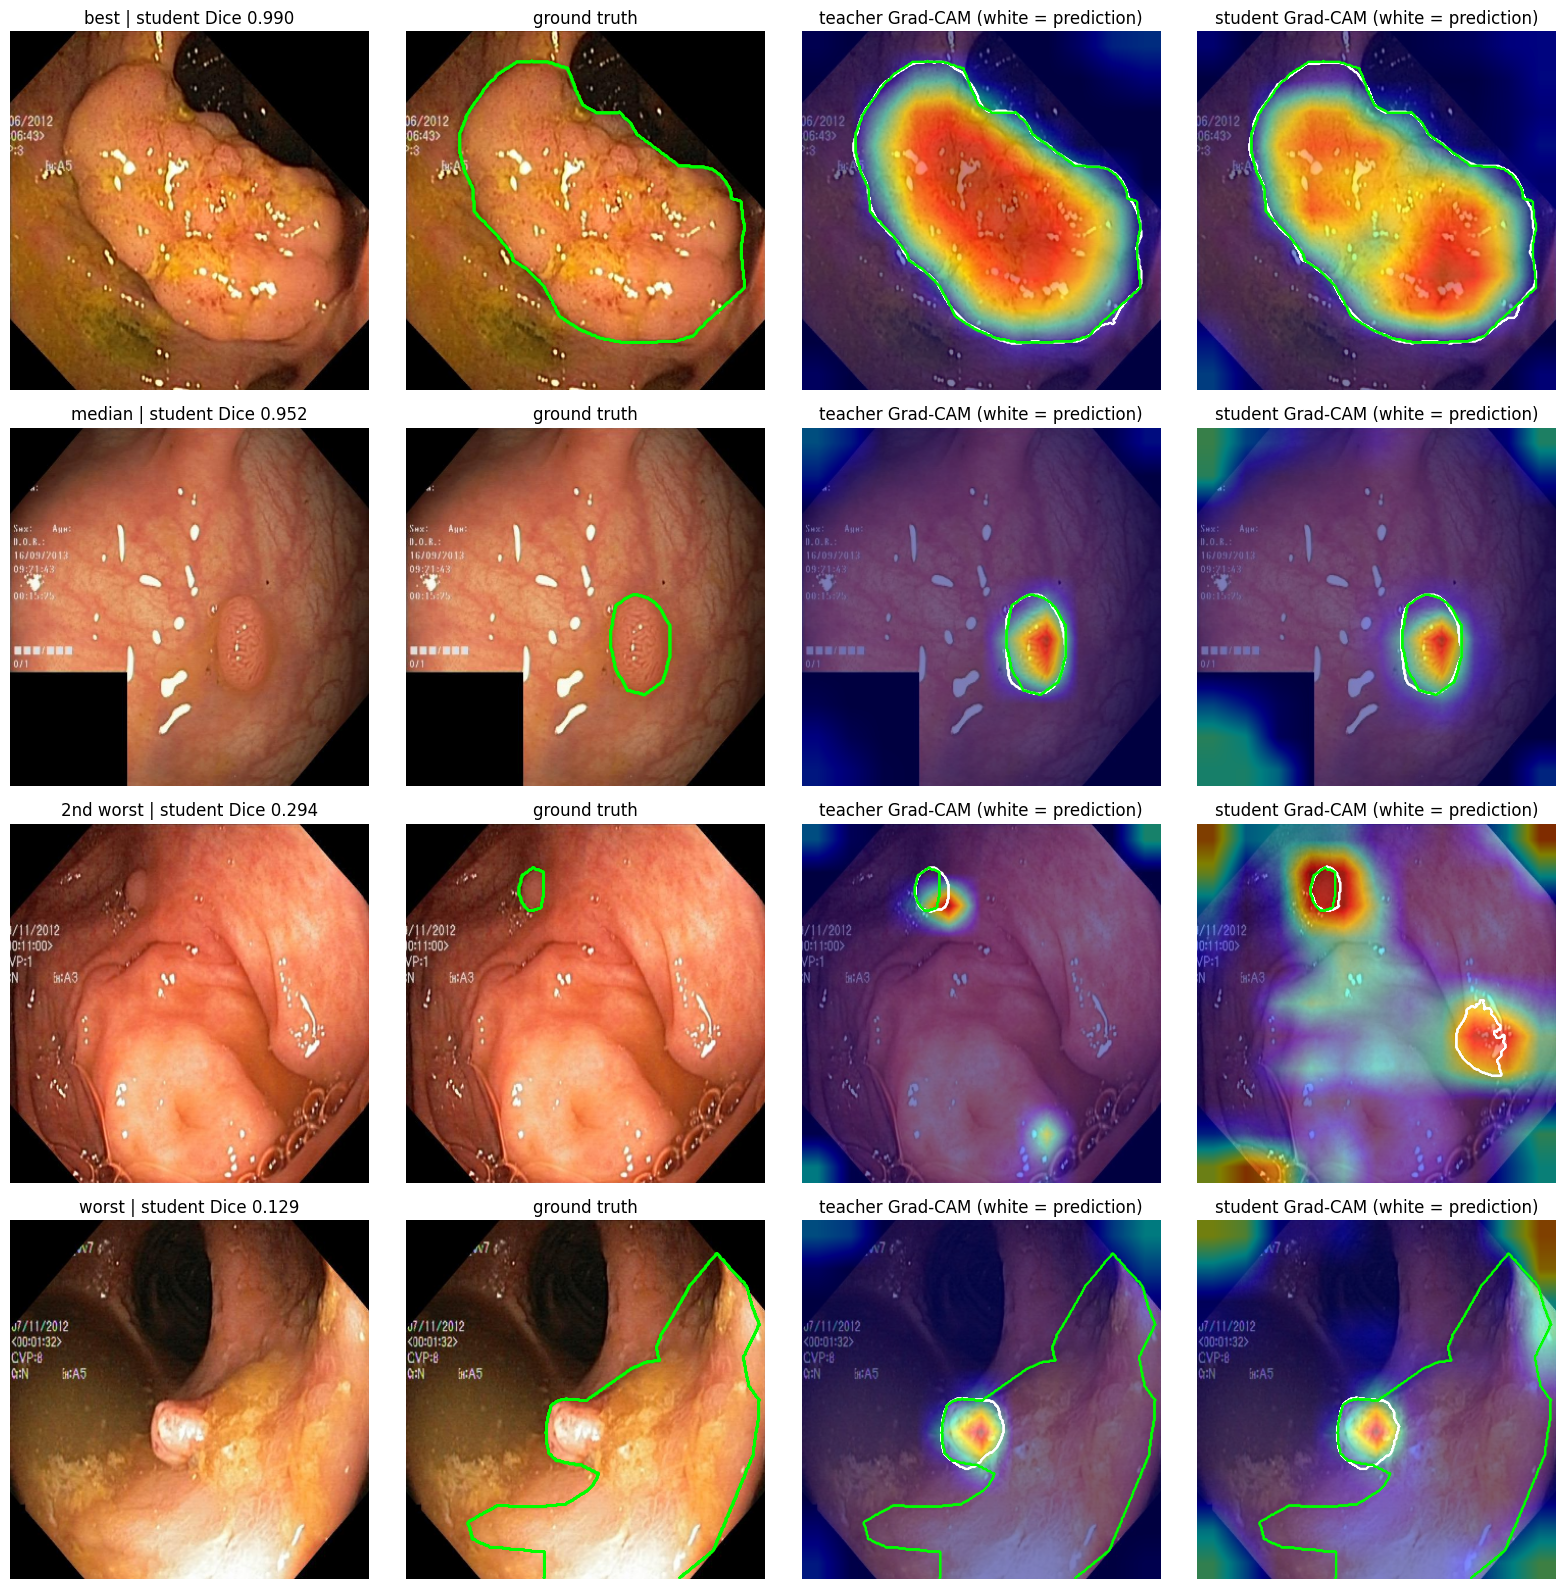

Saved gradcam.json + figures/gradcam_examples.png


In [ ]:
# Cell 10 — Grad-CAM: heatmap focus inside the polyp, teacher–student agreement, example figure
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import SemanticSegmentationTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Deepest encoder stage of each model (both at stride 32 -> 11x11 for a 352 input)
layers = {'teacher': teacher.encoder.layer4, 'student': student.encoder.features[-1]}
models = {'teacher': teacher.float().eval(), 'student': student.float().eval()}
cams = {k: GradCAM(model=models[k], target_layers=[layers[k]]) for k in models}

def run_cam(key, x):
    with torch.no_grad():
        pred = (torch.sigmoid(models[key](x))[0, 0] > 0.5).float().cpu().numpy()
    if pred.sum() == 0:
        return None, pred
    g = cams[key](input_tensor=x, targets=[SemanticSegmentationTarget(0, pred)])[0]
    return g, pred

energy = {'teacher': [], 'student': []}
chance, corr, store = [], [], {}
for k, i in enumerate(test_ids):
    img, gt = cache['test'][k]
    x = torch.from_numpy(test_inputs[i]).to(DEVICE)
    out = {key: run_cam(key, x) for key in models}
    if any(out[key][0] is None for key in models):
        continue
    gtf = gt.astype(np.float32)
    for key in models:
        g = out[key][0]
        energy[key].append(float((g * gtf).sum() / (g.sum() + 1e-7)))
    chance.append(float(gtf.mean()))
    corr.append(float(np.corrcoef(out['teacher'][0].ravel(), out['student'][0].ravel())[0, 1]))
    store[i] = (img, gt, out)

e_t, e_s = np.array(energy['teacher']), np.array(energy['student'])
print(f'Images with CAMs: {len(e_t)} / {len(test_ids)}')
print(f'Chance level (polyp share of image): {np.mean(chance):.3f}')
print(f'Energy in polyp  | teacher {e_t.mean():.3f} ± {e_t.std():.3f} | student {e_s.mean():.3f} ± {e_s.std():.3f}')
print(f'Teacher–student CAM correlation: mean {np.mean(corr):.3f} | median {np.median(corr):.3f}')
cam_stat = paired(e_s, e_t, 'CAM energy in polyp: student vs teacher')

# ---------- Example figure: best, median, two worst (by INT8 student test Dice) ----------
dice_s = per_img['student_mnv2_INT8']
order = [test_ids[j] for j in np.argsort(dice_s) if test_ids[j] in store]
picks = [order[-1], order[len(order) // 2], order[1], order[0]]
labels = ['best', 'median', '2nd worst', 'worst']

fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for r, (i, lab) in enumerate(zip(picks, labels)):
    img, gt, out = store[i]
    rgb = img.astype(np.float32) / 255
    axes[r, 0].imshow(img); axes[r, 0].set_title(f'{lab} | student Dice {dice_s[test_ids.index(i)]:.3f}')
    axes[r, 1].imshow(img); axes[r, 1].contour(gt, colors='lime', linewidths=1.5); axes[r, 1].set_title('ground truth')
    for c, key in [(2, 'teacher'), (3, 'student')]:
        g, pred = out[key]
        axes[r, c].imshow(show_cam_on_image(rgb, g, use_rgb=True))
        axes[r, c].contour(pred, colors='white', linewidths=1)
        axes[r, c].contour(gt, colors='lime', linewidths=1)
        axes[r, c].set_title(f'{key} Grad-CAM (white = prediction)')
    for a in axes[r]:
        a.axis('off')
plt.tight_layout()
plt.savefig(f'{PROJECT_DIR}/figures/gradcam_examples.png', dpi=110)
plt.show()

with open(f'{PROJECT_DIR}/results/gradcam.json', 'w') as f:
    json.dump(dict(layers='teacher: encoder.layer4, student: encoder.features[-1]',
                   n_images=len(e_t), chance=float(np.mean(chance)),
                   energy_teacher=float(e_t.mean()), energy_student=float(e_s.mean()),
                   cam_corr_mean=float(np.mean(corr)), cam_corr_median=float(np.median(corr)),
                   stat=cam_stat, picks=dict(zip(labels, picks))), f, indent=1)
print('Saved gradcam.json + figures/gradcam_examples.png')

In [12]:
# Cell 11 — C++ inference (ONNX Runtime C++ API + OpenCV), INT8 student, parity check vs Python
ORT_VER = '1.20.1'
CPP_DIR, OUT_DIR = '/content/cpp', '/content/cpp_out'
os.makedirs(CPP_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

!apt-get -qq install -y libopencv-dev > /dev/null
!wget -q https://github.com/microsoft/onnxruntime/releases/download/v{ORT_VER}/onnxruntime-linux-x64-{ORT_VER}.tgz -O /content/ort.tgz
!tar -xzf /content/ort.tgz -C /content

CPP_SRC = r'''
// segment.cpp — polyp segmentation with the ONNX Runtime C++ API
#include <onnxruntime_cxx_api.h>
#include <opencv2/opencv.hpp>
#include <algorithm>
#include <chrono>
#include <cmath>
#include <fstream>
#include <iostream>
#include <string>
#include <vector>

int main(int argc, char** argv) {
    if (argc < 5) {
        std::cerr << "usage: segment <model.onnx> <image_list.txt> <out_dir> <threads>\n";
        return 1;
    }
    const std::string model_path = argv[1], list_path = argv[2], out_dir = argv[3];
    const int threads = std::stoi(argv[4]);
    const int S = 352;
    const float mean[3] = {0.485f, 0.456f, 0.406f};
    const float stdv[3] = {0.229f, 0.224f, 0.225f};

    Ort::Env env(ORT_LOGGING_LEVEL_WARNING, "polyp");
    Ort::SessionOptions so;
    so.SetIntraOpNumThreads(threads);
    so.SetInterOpNumThreads(1);
    so.SetGraphOptimizationLevel(GraphOptimizationLevel::ORT_ENABLE_ALL);
    Ort::Session session(env, model_path.c_str(), so);
    Ort::MemoryInfo mem = Ort::MemoryInfo::CreateCpu(OrtArenaAllocator, OrtMemTypeDefault);

    const char* in_names[] = {"image"};
    const char* out_names[] = {"logits"};
    std::vector<int64_t> shape = {1, 3, S, S};
    std::vector<float> input(3 * S * S);

    std::ifstream list(list_path);
    std::string path;
    std::vector<double> times;
    while (std::getline(list, path)) {
        if (path.empty()) continue;
        cv::Mat bgr = cv::imread(path, cv::IMREAD_COLOR);
        const int H = bgr.rows, W = bgr.cols;

        auto t0 = std::chrono::high_resolution_clock::now();
        cv::Mat rgb, small;
        cv::cvtColor(bgr, rgb, cv::COLOR_BGR2RGB);
        cv::resize(rgb, small, cv::Size(S, S), 0, 0, cv::INTER_LINEAR);
        for (int y = 0; y < S; ++y) {
            const cv::Vec3b* row = small.ptr<cv::Vec3b>(y);
            for (int x = 0; x < S; ++x)
                for (int c = 0; c < 3; ++c)
                    input[c * S * S + y * S + x] = (row[x][c] / 255.0f - mean[c]) / stdv[c];
        }
        Ort::Value in = Ort::Value::CreateTensor<float>(mem, input.data(), input.size(),
                                                        shape.data(), shape.size());
        auto out = session.Run(Ort::RunOptions{nullptr}, in_names, &in, 1, out_names, 1);
        const float* logits = out[0].GetTensorData<float>();

        cv::Mat prob(S, S, CV_32F);
        for (int k = 0; k < S * S; ++k)
            prob.at<float>(k / S, k % S) = 1.0f / (1.0f + std::exp(-logits[k]));
        cv::Mat prob_full;
        cv::resize(prob, prob_full, cv::Size(W, H), 0, 0, cv::INTER_LINEAR);
        cv::Mat mask = prob_full > 0.5f;
        auto t1 = std::chrono::high_resolution_clock::now();
        times.push_back(std::chrono::duration<double, std::milli>(t1 - t0).count());

        std::string name = path.substr(path.find_last_of('/') + 1);
        name = name.substr(0, name.find_last_of('.')) + ".png";
        cv::imwrite(out_dir + "/" + name, mask);
    }

    std::sort(times.begin(), times.end());
    std::cout << "images " << times.size()
              << " | median " << times[times.size() / 2] << " ms"
              << " | p95 " << times[(size_t)(0.95 * (times.size() - 1))] << " ms"
              << " (end-to-end: preprocess + inference + postprocess)\n";
    return 0;
}
'''
with open(f'{CPP_DIR}/segment.cpp', 'w') as f:
    f.write(CPP_SRC)

ORT_HOME = f'/content/onnxruntime-linux-x64-{ORT_VER}'
!g++ -O3 -std=c++17 {CPP_DIR}/segment.cpp -o {CPP_DIR}/segment -I{ORT_HOME}/include -L{ORT_HOME}/lib -lonnxruntime $(pkg-config --cflags --libs opencv4) -Wl,-rpath,{ORT_HOME}/lib
print('Build OK' if os.path.exists(f'{CPP_DIR}/segment') else 'Build FAILED')

# Run on the 100 test images (original resolution), single thread
with open(f'{CPP_DIR}/test_list.txt', 'w') as f:
    f.write('\n'.join(f'{DATA_DIR}/images/{i}.jpg' for i in test_ids))
INT8_PATH = f'{ONNX_DIR}/student_mnv2_int8.onnx'
!{CPP_DIR}/segment {INT8_PATH} {CPP_DIR}/test_list.txt {OUT_DIR} 1

# Parity check: C++ masks vs Python ONNX Runtime masks, and Dice vs ground truth
sess = make_session(INT8_PATH, 1)
agree, d_cpp = [], []
for i in test_ids:
    g = orig_masks[i]
    m_cpp = cv2.imread(f'{OUT_DIR}/{i}.png', cv2.IMREAD_GRAYSCALE) > 127
    logits = sess.run(None, {'image': test_inputs[i]})[0]
    prob = cv2.resize(1 / (1 + np.exp(-logits[0, 0])), (g.shape[1], g.shape[0]), interpolation=cv2.INTER_LINEAR)
    agree.append((m_cpp == (prob > 0.5)).mean())
    d_cpp.append(dice_iou_np(m_cpp, g)[0])
print(f'C++ vs Python pixel agreement: mean {np.mean(agree)*100:.3f}% | min {np.min(agree)*100:.3f}%')
print(f'C++ test Dice: {np.mean(d_cpp):.4f}  (Python INT8: {np.mean(per_img["student_mnv2_INT8"]):.4f})')

os.makedirs(f'{PROJECT_DIR}/cpp', exist_ok=True)
shutil.copyfile(f'{CPP_DIR}/segment.cpp', f'{PROJECT_DIR}/cpp/segment.cpp')
print('Saved segment.cpp to Drive')

Build OK
images 100 | median 85.7418 ms | p95 138.321 ms (end-to-end: preprocess + inference + postprocess)
C++ vs Python pixel agreement: mean 100.000% | min 100.000%
C++ test Dice: 0.8919  (Python INT8: 0.8919)
Saved segment.cpp to Drive


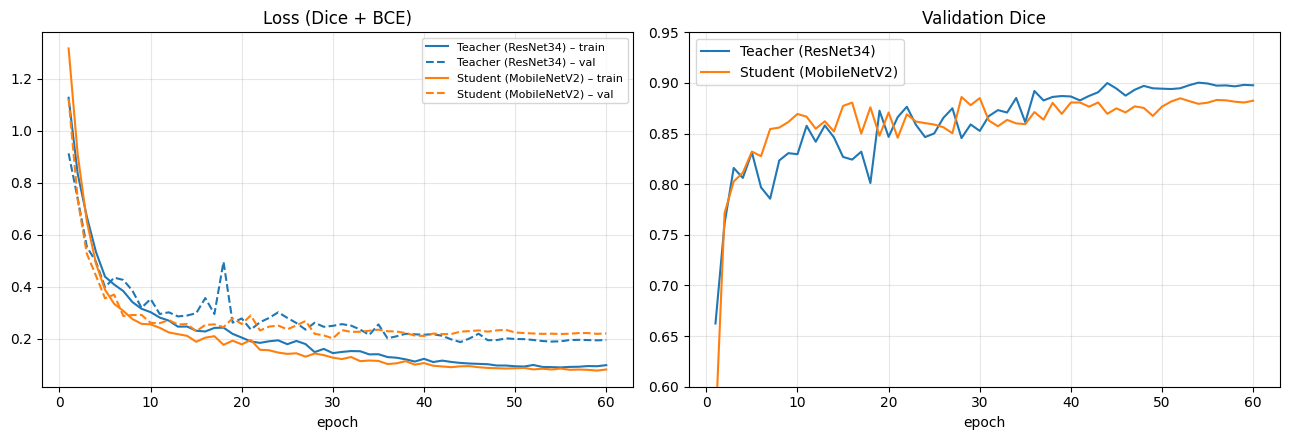

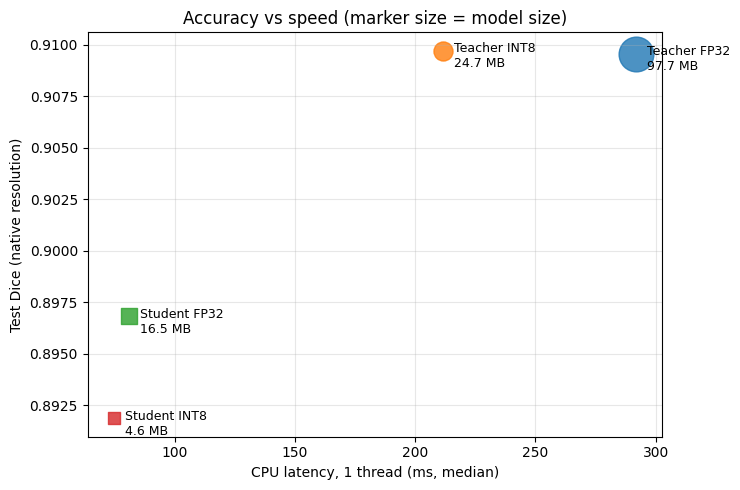

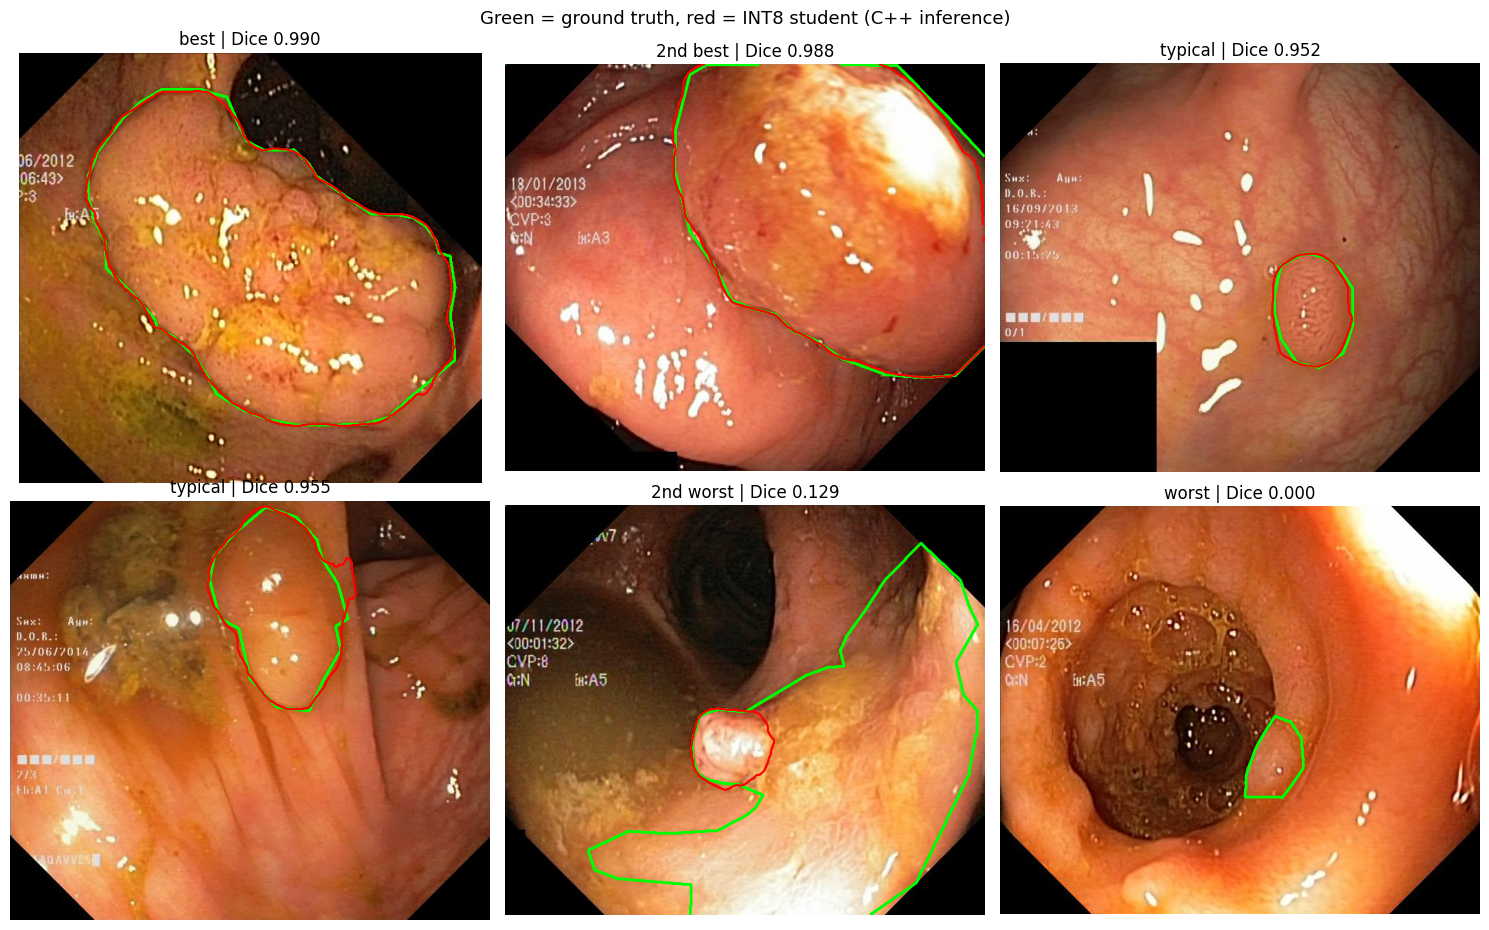

  cpp/segment.cpp                                 0.00 MB
  figures/augmented_batch.png                     0.69 MB
  figures/gradcam_examples.png                    2.36 MB
  figures/predictions.png                         1.95 MB
  figures/samples.png                             1.51 MB
  figures/tradeoff.png                            0.05 MB
  figures/training_curves.png                     0.11 MB
  results/final_benchmark.json                    0.02 MB
  results/gradcam.json                            0.00 MB
  results/kd_multiseed.json                       0.02 MB
  results/split.json                              0.03 MB
  results/student_mnv2_plain_s43_history.json     0.01 MB
  results/teacher_r34_v2_history.json             0.01 MB
  models/student_mnv2_int8.onnx                   4.55 MB

Saved /content/drive/MyDrive/IPCVai_MedSeg/repo_export.zip


In [13]:
# Cell 12 — README figures + export package for GitHub
REPO = '/content/repo_export'
for sub in ['figures', 'results', 'models', 'cpp']:
    os.makedirs(f'{REPO}/{sub}', exist_ok=True)

bench = json.load(open(f'{PROJECT_DIR}/results/final_benchmark.json'))

# ---------- 1. Training curves ----------
def load_hist(name):
    return json.load(open(f'{PROJECT_DIR}/results/{name}_history.json'))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, lab, c in [('teacher_r34_v2', 'Teacher (ResNet34)', 'tab:blue'),
                     ('student_mnv2_plain_s43', 'Student (MobileNetV2)', 'tab:orange')]:
    h = load_hist(name); ep = [r['epoch'] for r in h]
    ax[0].plot(ep, [r['train_loss'] for r in h], color=c, label=f'{lab} – train')
    ax[0].plot(ep, [r['val_loss'] for r in h], color=c, ls='--', label=f'{lab} – val')
    ax[1].plot(ep, [r['val_dice'] for r in h], color=c, label=lab)
ax[0].set(title='Loss (Dice + BCE)', xlabel='epoch'); ax[0].legend(fontsize=8)
ax[1].set(title='Validation Dice', xlabel='epoch', ylim=(0.6, 0.95)); ax[1].legend()
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{REPO}/figures/training_curves.png', dpi=120); plt.show()

# ---------- 2. Accuracy–speed trade-off ----------
fig, ax = plt.subplots(figsize=(7.5, 5))
for r in bench['rows']:
    name = ('Teacher' if 'teacher' in r['model'] else 'Student') + f" {r['precision']}"
    mk = 'o' if 'teacher' in r['model'] else 's'
    ax.scatter(r['lat1_med'], r['test_dice'], s=40 + r['size_mb'] * 6, marker=mk, alpha=0.8)
    ax.annotate(f"{name}\n{r['size_mb']:.1f} MB", (r['lat1_med'], r['test_dice']),
                textcoords='offset points', xytext=(8, -12), fontsize=9)
ax.set(xlabel='CPU latency, 1 thread (ms, median)', ylabel='Test Dice (native resolution)',
       title='Accuracy vs speed (marker size = model size)')
ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{REPO}/figures/tradeoff.png', dpi=120); plt.show()

# ---------- 3. Prediction gallery (C++ INT8 output) ----------
dice_s = np.array(per_img['student_mnv2_INT8'])
order = [test_ids[j] for j in np.argsort(dice_s)]
picks = [order[-1], order[-2], order[len(order) // 2], order[len(order) // 2 + 1], order[1], order[0]]
tags = ['best', '2nd best', 'typical', 'typical', '2nd worst', 'worst']
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for a, i, tag in zip(axes.ravel(), picks, tags):
    img = cv2.cvtColor(cv2.imread(f'{DATA_DIR}/images/{i}.jpg'), cv2.COLOR_BGR2RGB)
    m_cpp = cv2.imread(f'{OUT_DIR}/{i}.png', cv2.IMREAD_GRAYSCALE) > 127
    a.imshow(img)
    a.contour(orig_masks[i], colors='lime', linewidths=2)
    a.contour(m_cpp, colors='red', linewidths=1.5)
    a.set_title(f'{tag} | Dice {dice_s[test_ids.index(i)]:.3f}'); a.axis('off')
fig.suptitle('Green = ground truth, red = INT8 student (C++ inference)', fontsize=13)
plt.tight_layout(); plt.savefig(f'{REPO}/figures/predictions.png', dpi=110); plt.show()

# ---------- 4. Collect files ----------
for fn in ['samples.png', 'augmented_batch.png', 'gradcam_examples.png']:
    shutil.copyfile(f'{PROJECT_DIR}/figures/{fn}', f'{REPO}/figures/{fn}')
for fn in ['final_benchmark.json', 'kd_multiseed.json', 'gradcam.json',
           'teacher_r34_v2_history.json', 'student_mnv2_plain_s43_history.json']:
    shutil.copyfile(f'{PROJECT_DIR}/results/{fn}', f'{REPO}/results/{fn}')
shutil.copyfile(f'{PROJECT_DIR}/data/split.json', f'{REPO}/results/split.json')
shutil.copyfile(f'{ONNX_DIR}/student_mnv2_int8.onnx', f'{REPO}/models/student_mnv2_int8.onnx')
shutil.copyfile(f'{CPP_DIR}/segment.cpp', f'{REPO}/cpp/segment.cpp')

shutil.make_archive(f'{PROJECT_DIR}/repo_export', 'zip', REPO)
for root, _, files in os.walk(REPO):
    for fn in sorted(files):
        p = os.path.join(root, fn)
        print(f'  {os.path.relpath(p, REPO):<45} {os.path.getsize(p)/1e6:6.2f} MB')
print(f'\nSaved {PROJECT_DIR}/repo_export.zip')